In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.preprocessing import PolynomialFeatures
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

In [2]:
np.random.seed(42)
x = 2 * np.random.rand(100, 1)
y = 4 + 3 * x + np.random.randn(100, 1)

In [3]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

Linear Regression MSE: 0.65, R^2: 0.81
Coefficients: 2.80, Intercept: 4.14


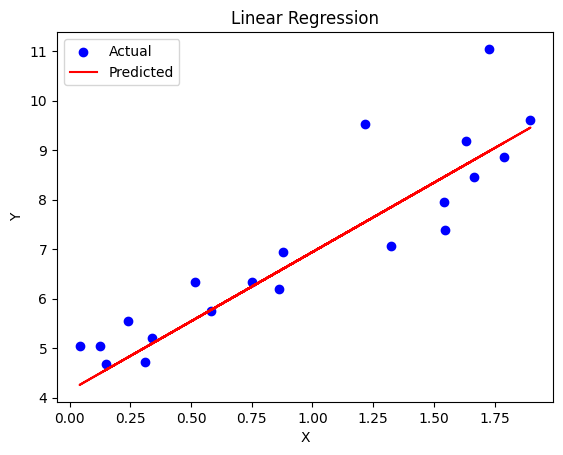

In [4]:
lr = LinearRegression()
lr.fit(x_train, y_train)
y_pred = lr.predict(x_test)

mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Linear Regression MSE: {mse:.2f}, R^2: {r2:.2f}")
print(f"Coefficients: {lr.coef_[0][0]:.2f}, Intercept: {lr.intercept_[0]:.2f}")

plt.scatter(x_test, y_test, color='blue', label='Actual')
plt.plot(x_test, y_pred, color='red', label='Predicted')
plt.xlabel('X')
plt.ylabel('Y')
plt.title('Linear Regression')
plt.legend()
plt.show()

In [6]:
np.random.seed(0)
x = np.random.rand(100, 3)
y = 4 + np.dot(x, np.array([2, 3, 4])) + np.random.randn(100)

In [10]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

lr = LinearRegression()
lr.fit(x_train, y_train)
y_pred = lr.predict(x_test)

mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Linear Regression MSE: {mse:.2f}, R^2: {r2:.2f}")
print(f"Coefficients: {lr.coef_}, Intercept: {lr.intercept_:.2f}")

Linear Regression MSE: 1.10, R^2: 0.67
Coefficients: [1.86875977 2.76007822 4.08711696], Intercept: 4.02


In [11]:
np.random.seed(42)
x = 5 * np.random.rand(100, 1) - 4
y = 0.4 + x**2 + np.random.randn(100, 1)

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

Polynomial Regression MSE: 0.64, R^2: 0.98
Coefficients: [0.22199346 1.09685762], Intercept: 0.25


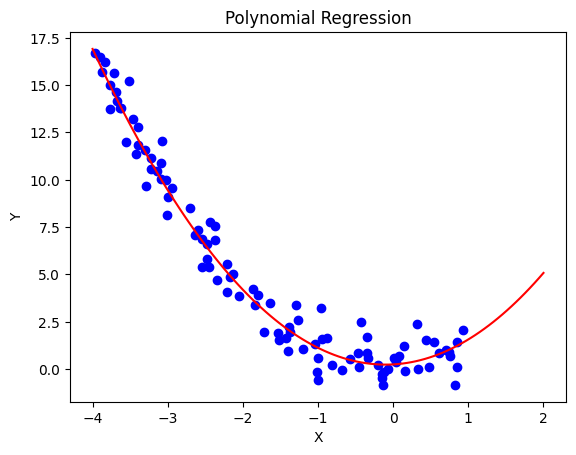

In [14]:
plr_fit = PolynomialFeatures(degree=2, include_bias=False)

x_train_poly = plr_fit.fit_transform(x_train)
x_test_poly = plr_fit.transform(x_test)

lr = LinearRegression()
lr.fit(x_train_poly, y_train)
y_pred = lr.predict(x_test_poly)

mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Polynomial Regression MSE: {mse:.2f}, R^2: {r2:.2f}")
print(f"Coefficients: {lr.coef_[0]}, Intercept: {lr.intercept_[0]:.2f}")

x_plot = np.linspace(-4, 2, 100).reshape(-1, 1)
x_plot_poly = plr_fit.transform(x_plot)
y_plot = lr.predict(x_plot_poly)

plt.scatter(x, y, color='blue')
plt.plot(x_plot, y_plot, color='red')
plt.title("Polynomial Regression")
plt.xlabel("X")
plt.ylabel("Y")
plt.show()

In [15]:
lasso = Lasso(alpha=0.1)
lasso.fit(x_train_poly, y_train)
y_pred = lasso.predict(x_test_poly)

mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Lasso Regression MSE: {mse:.2f}, R^2: {r2:.2f}")
print(f"Coefficients: {lasso.coef_[0]}, Intercept: {lasso.intercept_[0]:.2f}")


Lasso Regression MSE: 0.64, R^2: 0.98
Coefficients: 0.0, Intercept: 0.20


In [16]:
ridge = Ridge(alpha=0.1)
ridge.fit(x_train_poly, y_train)
y_pred = ridge.predict(x_test_poly)

mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Ridge Regression MSE: {mse:.2f}, R^2: {r2:.2f}")
print(f"Coefficients: {ridge.coef_[0]}, Intercept: {ridge.intercept_[0]:.2f}")


Ridge Regression MSE: 0.64, R^2: 0.98
Coefficients: 0.21988501311605277, Intercept: 0.25


In [17]:
# implement ols manualy

x_intercept = np.c_[np.ones((x_train.shape[0], 1)), x_train_poly]
beta_hat = np.linalg.inv(x_intercept.T @ x_intercept) @ (x_intercept.T @ y_train)  # dot product

print(f"Coefficients: {beta_hat.flatten()}")

sklearn_lr = LinearRegression(fit_intercept=True)
sklearn_lr.fit(x_train_poly, y_train)
print(f"Sklearn Coefficients: {sklearn_lr.coef_.flatten()}, Intercept: {sklearn_lr.intercept_[0]:.2f}")

Coefficients: [0.25131874 0.22199346 1.09685762]
Sklearn Coefficients: [0.22199346 1.09685762], Intercept: 0.25


In [19]:
from scipy import stats

def calculate_pvalues(X, y, model):
    n = X.shape[0]
    p = X.shape[1]
    X_with_intercept = np.column_stack([np.ones(n), X])
    mse = np.sum((y - model.predict(X)) ** 2) / (n - p - 1)
    var_b = mse * np.linalg.inv(np.dot(X_with_intercept.T, X_with_intercept)).diagonal()
    sd_b = np.sqrt(var_b)
    t_stat = model.coef_ / sd_b[1:]
    p_values = 2 * (1 - stats.t.cdf(np.abs(t_stat), n - p - 1))
    return p_values


np.random.seed(0)
X = np.random.rand(100, 3)
y = 2 + 3*X[:, 0] + 4*X[:, 1] + 5*X[:, 2] + np.random.randn(100)


model = LinearRegression()
model.fit(X, y)

# Calculate p-values
p_values = calculate_pvalues(X, y, model)

print("Coefficients:")
for i, (coef, p_val) in enumerate(zip(model.coef_, p_values)):
    print(f"x{i+1}: {coef:.4f} (p-value: {p_val:.4f})")
print(f"Intercept: {model.intercept_:.4f}")

# interpret p-values
for i, (coef, p_val) in enumerate(zip(model.coef_, p_values)):
    if p_val < 0.05:
        print(f"x{i+1} is statistically significant (p-value: {p_val:.4f})")
    else:
        print(f"x{i+1} is not statistically significant (p-value >= 0.05)")


Coefficients:
x1: 2.5913 (p-value: 0.0000)
x2: 3.9800 (p-value: 0.0000)
x3: 5.2532 (p-value: 0.0000)
Intercept: 1.9502
x1 is statistically significant (p-value: 0.0000)
x2 is statistically significant (p-value: 0.0000)
x3 is statistically significant (p-value: 0.0000)


In [20]:
np.random.seed(0)
X = np.random.rand(100, 2)
y = 1 + 2*X[:, 0] + 3*X[:, 1] + 4*X[:, 0]*X[:, 1] + np.random.randn(100)*0.1

# Create interaction term
X_interact = np.column_stack([X, X[:, 0] * X[:, 1]])

X_train, X_test, y_train, y_test = train_test_split(X_interact, y, test_size=0.2, random_state=42)

model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Coefficients:")
print(f"X1: {model.coef_[0]:.4f}")
print(f"X2: {model.coef_[1]:.4f}")
print(f"X1*X2 (interaction): {model.coef_[2]:.4f}")
print(f"Intercept: {model.intercept_:.4f}")
print(f"R-squared: {r2_score(y_test, y_pred):.4f}")

print("\nInterpretation:")
print("The effect of X1 on y depends on the value of X2, and vice versa.")
print(f"When X2 is 0, a one-unit increase in X1 is associated with a {model.coef_[0]:.4f} increase in y.")
print(f"When X1 is 0, a one-unit increase in X2 is associated with a {model.coef_[1]:.4f} increase in y.")
print(f"The interaction term {model.coef_[2]:.4f} represents how the effect of X1 changes for each one-unit increase in X2 (and vice versa).")


Coefficients:
X1: 1.9177
X2: 2.9715
X1*X2 (interaction): 4.0758
Intercept: 1.0242
R-squared: 0.9972

Interpretation:
The effect of X1 on y depends on the value of X2, and vice versa.
When X2 is 0, a one-unit increase in X1 is associated with a 1.9177 increase in y.
When X1 is 0, a one-unit increase in X2 is associated with a 2.9715 increase in y.
The interaction term 4.0758 represents how the effect of X1 changes for each one-unit increase in X2 (and vice versa).


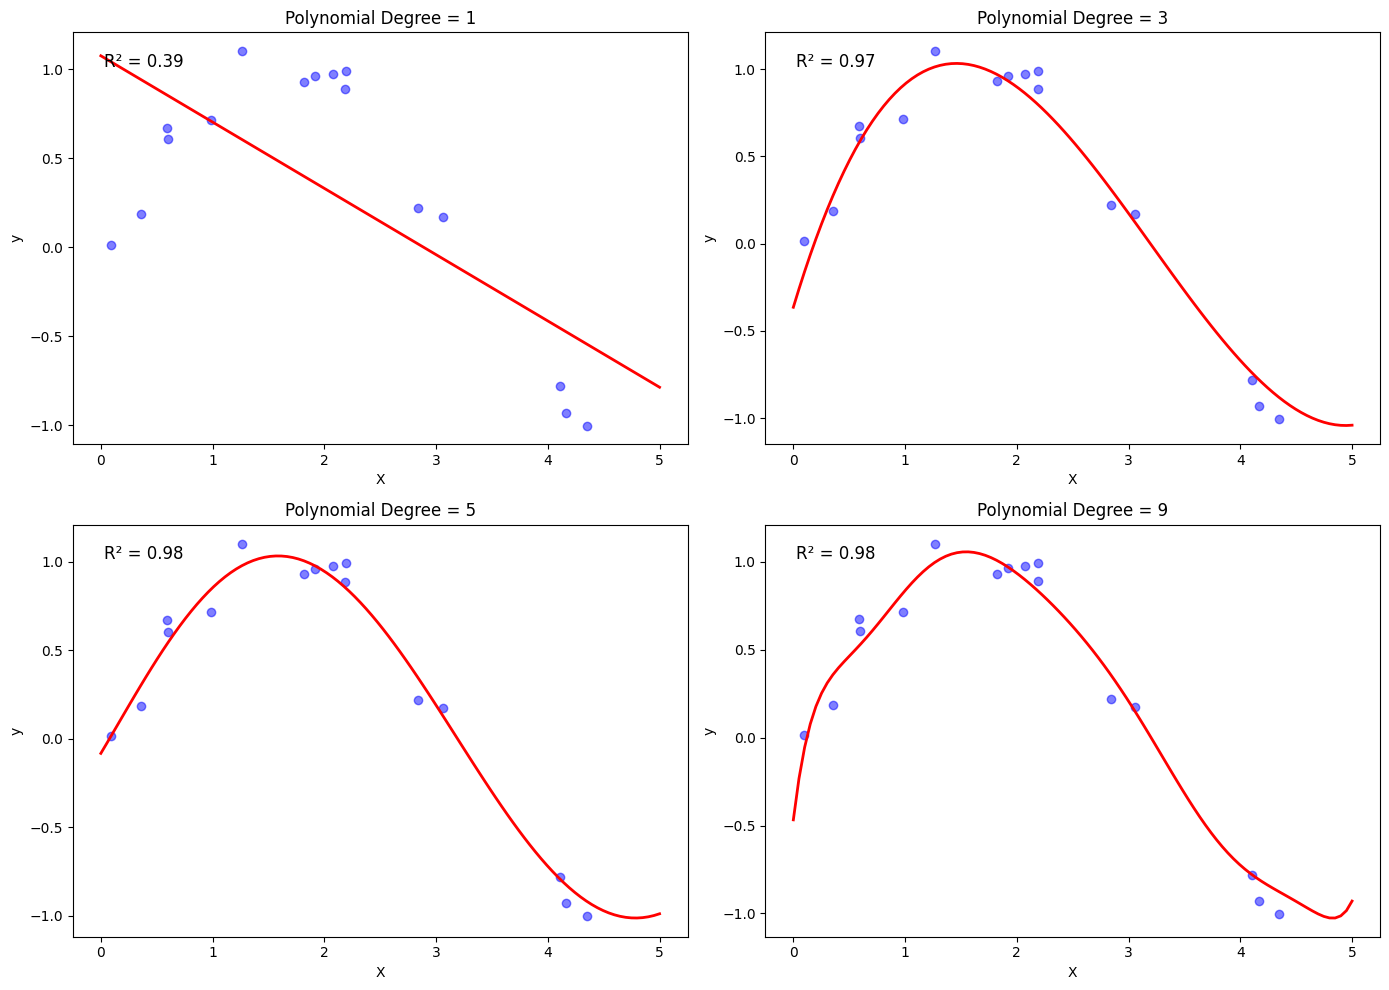

In [21]:
np.random.seed(0)
X = np.sort(5 * np.random.rand(80, 1), axis=0)
y = np.sin(X).ravel() + np.random.normal(0, 0.1, X.shape[0])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

degrees = [1, 3, 5, 9]

plt.figure(figsize=(14, 10))
for i, degree in enumerate(degrees):
    ax = plt.subplot(2, 2, i + 1)

    poly_features = PolynomialFeatures(degree=degree, include_bias=False)
    X_poly_train = poly_features.fit_transform(X_train)
    X_poly_test = poly_features.transform(X_test)

    model = LinearRegression()
    model.fit(X_poly_train, y_train)

    y_pred = model.predict(X_poly_test)

    X_plot = np.linspace(0, 5, 100).reshape(-1, 1)
    X_plot_poly = poly_features.transform(X_plot)
    y_plot = model.predict(X_plot_poly)

    plt.scatter(X_test, y_test, color='blue', alpha=0.5)
    plt.plot(X_plot, y_plot, color='red', linewidth=2)
    plt.title(f"Polynomial Degree = {degree}")
    plt.xlabel("X")
    plt.ylabel("y")
    plt.text(0.05, 0.95, f"R² = {r2_score(y_test, y_pred):.2f}", transform=ax.transAxes, fontsize=12, verticalalignment='top')

plt.tight_layout()
plt.show()
